In [3]:
import pandas as pd
csv_df = pd.read_csv("retail_orders.csv")
excel_df = pd.read_excel("retail_orders.xlsx", sheet_name="Data")
json_df = pd.read_json("retail_orders.json", orient="records")
tsv_df = pd.read_csv("retail_orders.tsv", sep="\t")
for name, frame in [("CSV", csv_df), ("Excel", excel_df),
                    ("JSON", json_df), ("TSV", tsv_df)]:
    print(name, frame.shape, frame.columns.tolist())
df = csv_df.copy()


CSV (75, 7) ['order_id', 'order_date', 'category', 'unit_price', 'quantity', 'discount_percent', 'city']
Excel (75, 7) ['order_id', 'order_date', 'category', 'unit_price', 'quantity', 'discount_percent', 'city']
JSON (75, 7) ['order_id', 'order_date', 'category', 'unit_price', 'quantity', 'discount_percent', 'city']
TSV (75, 7) ['order_id', 'order_date', 'category', 'unit_price', 'quantity', 'discount_percent', 'city']


In [4]:
df.head()

,order_id,order_date,category,unit_price,quantity,discount_percent,city
0,2001,2026-01-01,Electronics,132,3.0,15.0,riyadh
1,2002,2026-01-02,Home,121,4.0,0.0,riyadh
2,2003,invalid-date,Books,268,2.0,5.0,riyadh
3,2004,2026-01-04,home,42,5.0,10.0,riyadh
4,2005,2026-01-05,electronics,225,3.0,5.0,Jeddah


In [5]:
print(df.shape)

(75, 7)


In [6]:
print(df.isnull().sum())

order_id            0
order_date          0
category            0
unit_price          1
quantity            1
discount_percent    1
city                1
dtype: int64


In [7]:
null_per_row = df.isnull().sum(axis=1)
print("Number of nulls per row (value counts):")
print(null_per_row.value_counts())

print("\nRows with at least one null value:")
display(df[df.isnull().any(axis=1)])

Number of nulls per row (value counts):
0    71
1     4
Name: count, dtype: int64

Rows with at least one null value:


,order_id,order_date,category,unit_price,quantity,discount_percent,city
7,2008,2026-01-08,electronics,NaN,5.0,15.0,riyadh
11,2012,2026-01-12,Home,83,NaN,0.0,Riyadh
22,2023,2026-01-23,electronics,220,1.0,NaN,riyadh
26,2027,2026-01-27,books,95,4.0,0.0,NaN


In [8]:
num_duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {num_duplicates}")

Number of duplicate rows: 3


In [9]:
df = df.drop_duplicates()
df.shape

(72, 7)

In [10]:
print(df.columns.tolist())
display(df.dtypes)

['order_id', 'order_date', 'category', 'unit_price', 'quantity', 'discount_percent', 'city']


,0
order_id,int64
order_date,object
category,object
unit_price,object
quantity,float64
discount_percent,float64
city,object


In [11]:
# Clean 'category' column
df['category'] = df['category'].astype(str).str.strip().str.lower()

# Fill null values in 'city' with 'unknown', then clean 'city' column
df['city'] = df['city'].fillna('unknown').astype(str).str.strip().str.lower()

# Display unique values to verify
print("Unique Categories:", df['category'].unique())
print("Unique Cities:", df['city'].unique())
display(df.head())

Unique Categories: ['electronics' 'home' 'books']
Unique Cities: ['riyadh' 'jeddah' 'unknown']


,order_id,order_date,category,unit_price,quantity,discount_percent,city
0,2001,2026-01-01,electronics,132,3.0,15.0,riyadh
1,2002,2026-01-02,home,121,4.0,0.0,riyadh
2,2003,invalid-date,books,268,2.0,5.0,riyadh
3,2004,2026-01-04,home,42,5.0,10.0,riyadh
4,2005,2026-01-05,electronics,225,3.0,5.0,jeddah


In [12]:
# Convert order_date to datetime, invalid dates become NaT
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

# Count the number of invalid (NaT) dates
invalid_dates_count = df['order_date'].isna().sum()
print(f"Number of invalid dates (NaT): {invalid_dates_count}")

# Display rows with invalid dates
print("\nRows with invalid dates:")
display(df[df['order_date'].isna()])

Number of invalid dates (NaT): 1

Rows with invalid dates:


,order_id,order_date,category,unit_price,quantity,discount_percent,city
2,2003,NaT,books,268,2.0,5.0,riyadh


In [13]:
# 1. Keep a copy of the DataFrame with invalid dates before dropping them
df_with_invalid_dates = df.copy()

# 2. Correctly drop the rows where 'order_date' is NaT
df = df.dropna(subset=['order_date'])

# 3. Verify that there are no remaining invalid dates in df
invalid_count = df['order_date'].isna().sum()
print("Invalid dates in cleaned df:", invalid_count)
print("Cleaned DataFrame shape:", df.shape)

Invalid dates in cleaned df: 0
Cleaned DataFrame shape: (71, 7)


In [14]:
invalid_count = df_with_invalid_dates['order_date'].isna().sum()
print("Invalid dates:", invalid_count)

Invalid dates: 1


In [15]:
import numpy as np

# 1. Convert columns to numeric, coercing invalid non-numeric values to NaN
for col in ['unit_price', 'quantity', 'discount_percent']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 2. convert discount_percent
df.loc[
    (df['discount_percent'] > 100) | (df['discount_percent'] < 0),
    'discount_percent'
] = np.nan

# 3. convert quantity

df.loc[
    (df['quantity'] <= 0),
    'quantity'
] = np.nan

# convert unit price

df.loc[
    (df['unit_price'] <= 0),
    'unit_price'
] = np.nan

# 5. Display the cleaned summary statistics for these columns
print(df[['unit_price', 'quantity', 'discount_percent']].describe())
print("\nMissing values count per numeric column:")
print(df[['unit_price', 'quantity', 'discount_percent']].isna().sum())

       unit_price   quantity  discount_percent
count   68.000000  69.000000         69.000000
mean   144.117647   3.202899          6.739130
std     90.913364   1.430546          6.113274
min     16.000000   1.000000          0.000000
25%     57.500000   2.000000          0.000000
50%    130.000000   3.000000          5.000000
75%    226.500000   4.000000         15.000000
max    300.000000   5.000000         15.000000

Missing values count per numeric column:
unit_price          3
quantity            2
discount_percent    2
dtype: int64


In [16]:
for col in ['unit_price' , 'quantity' , 'discount_percent']:
  median = df[col].median()
  print(f"{col} has {df[col].isnull().sum()} missing values. filled with median {median}")
  df[col] = df[col].fillna(median)



unit_price has 3 missing values. filled with median 130.0
quantity has 2 missing values. filled with median 3.0
discount_percent has 2 missing values. filled with median 5.0


In [17]:
df['net_sales'] = df['unit_price'] * df['quantity'] * (1 - (df['discount_percent']/100))

In [18]:
df['net_sales'].head()

,net_sales
0,336.60
1,484.00
3,189.00
4,641.25
5,260.00


In [19]:
# Create a 'month' column extracting the month name from 'order_date'
df['month'] = df['order_date'].dt.strftime('%B')

# Display the unique months and a preview of the columns
print("Unique months in dataset:", df['month'].unique())
display(df[['order_date', 'month']].head())

Unique months in dataset: ['January' 'February' 'March']


,order_date,month
0,2026-01-01,January
1,2026-01-02,January
3,2026-01-04,January
4,2026-01-05,January
5,2026-01-06,January


In [20]:
df.head()

,order_id,order_date,category,unit_price,quantity,discount_percent,city,net_sales,month
0,2001,2026-01-01,electronics,132.0,3.0,15.0,riyadh,336.60,January
1,2002,2026-01-02,home,121.0,4.0,0.0,riyadh,484.00,January
3,2004,2026-01-04,home,42.0,5.0,10.0,riyadh,189.00,January
4,2005,2026-01-05,electronics,225.0,3.0,5.0,jeddah,641.25,January
5,2006,2026-01-06,books,130.0,2.0,0.0,riyadh,260.00,January


In [21]:
# 1. Group valid dates by month and sum net_sales
monthly_sales = df.groupby('month', sort=False)['net_sales'].sum().reset_index()
print("--- Monthly Net Sales ---")
print(monthly_sales)
print("\n")

# 2. Create a city by category table of order counts using pd.crosstab
# We count unique orders (order_id), so we pass values=df['order_id'] and aggfunc='nunique'
city_category_crosstab = pd.crosstab(
    index=df['city'],
    columns=df['category'],
    values=df['order_id'],
    aggfunc='nunique',
    margins=True,
    margins_name='Total'
).fillna(0).astype(int)

print("--- City by Category Order Counts ---")
display(city_category_crosstab)

--- Monthly Net Sales ---
      month  net_sales
0   January   12160.55
1  February   12772.45
2     March    5836.05


--- City by Category Order Counts ---


category,books,electronics,home,Total
city,,,,
jeddah,13,9,9,31
riyadh,14,10,15,39
unknown,1,0,0,1
Total,28,19,24,71


In [22]:
# 1. Confirm that numeric columns have no missing values
missing_numeric = df[['unit_price', 'quantity', 'discount_percent']].isna().sum()
print("Missing values in numeric columns:\n", missing_numeric)

# 2. Confirm numeric ranges are valid
print("\nNumeric range validation (min & max):")
print(df[['unit_price', 'quantity', 'discount_percent']].agg(['min', 'max']))

# 3. Confirm identifiers (order_id) remain unique
is_unique = df['order_id'].is_unique
print(f"\nAre order identifiers unique?: {is_unique}")

# 4. Export the clean dataset to CSV
df.to_csv('retail_orders_clean.csv', index=False)
print("\nSuccessfully exported 'retail_orders_clean.csv'")

# 5. Report the number of rows excluded from the monthly chart
# Original rows loaded was 75
original_rows = 75
cleaned_rows = len(df)
excluded_rows = original_rows - cleaned_rows
print(f"\nTotal rows in raw data: {original_rows}")
print(f"Total rows in cleaned monthly chart data: {cleaned_rows}")
print(f"Number of rows excluded from the monthly chart: {excluded_rows}")

Missing values in numeric columns:
 unit_price          0
quantity            0
discount_percent    0
dtype: int64

Numeric range validation (min & max):
     unit_price  quantity  discount_percent
min        16.0       1.0               0.0
max       300.0       5.0              15.0

Are order identifiers unique?: True

Successfully exported 'retail_orders_clean.csv'

Total rows in raw data: 75
Total rows in cleaned monthly chart data: 71
Number of rows excluded from the monthly chart: 4


/tmp/ipykernel_1876/3263331039.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0, 0], data=df, x='category', y='unit_price', palette='Set2')


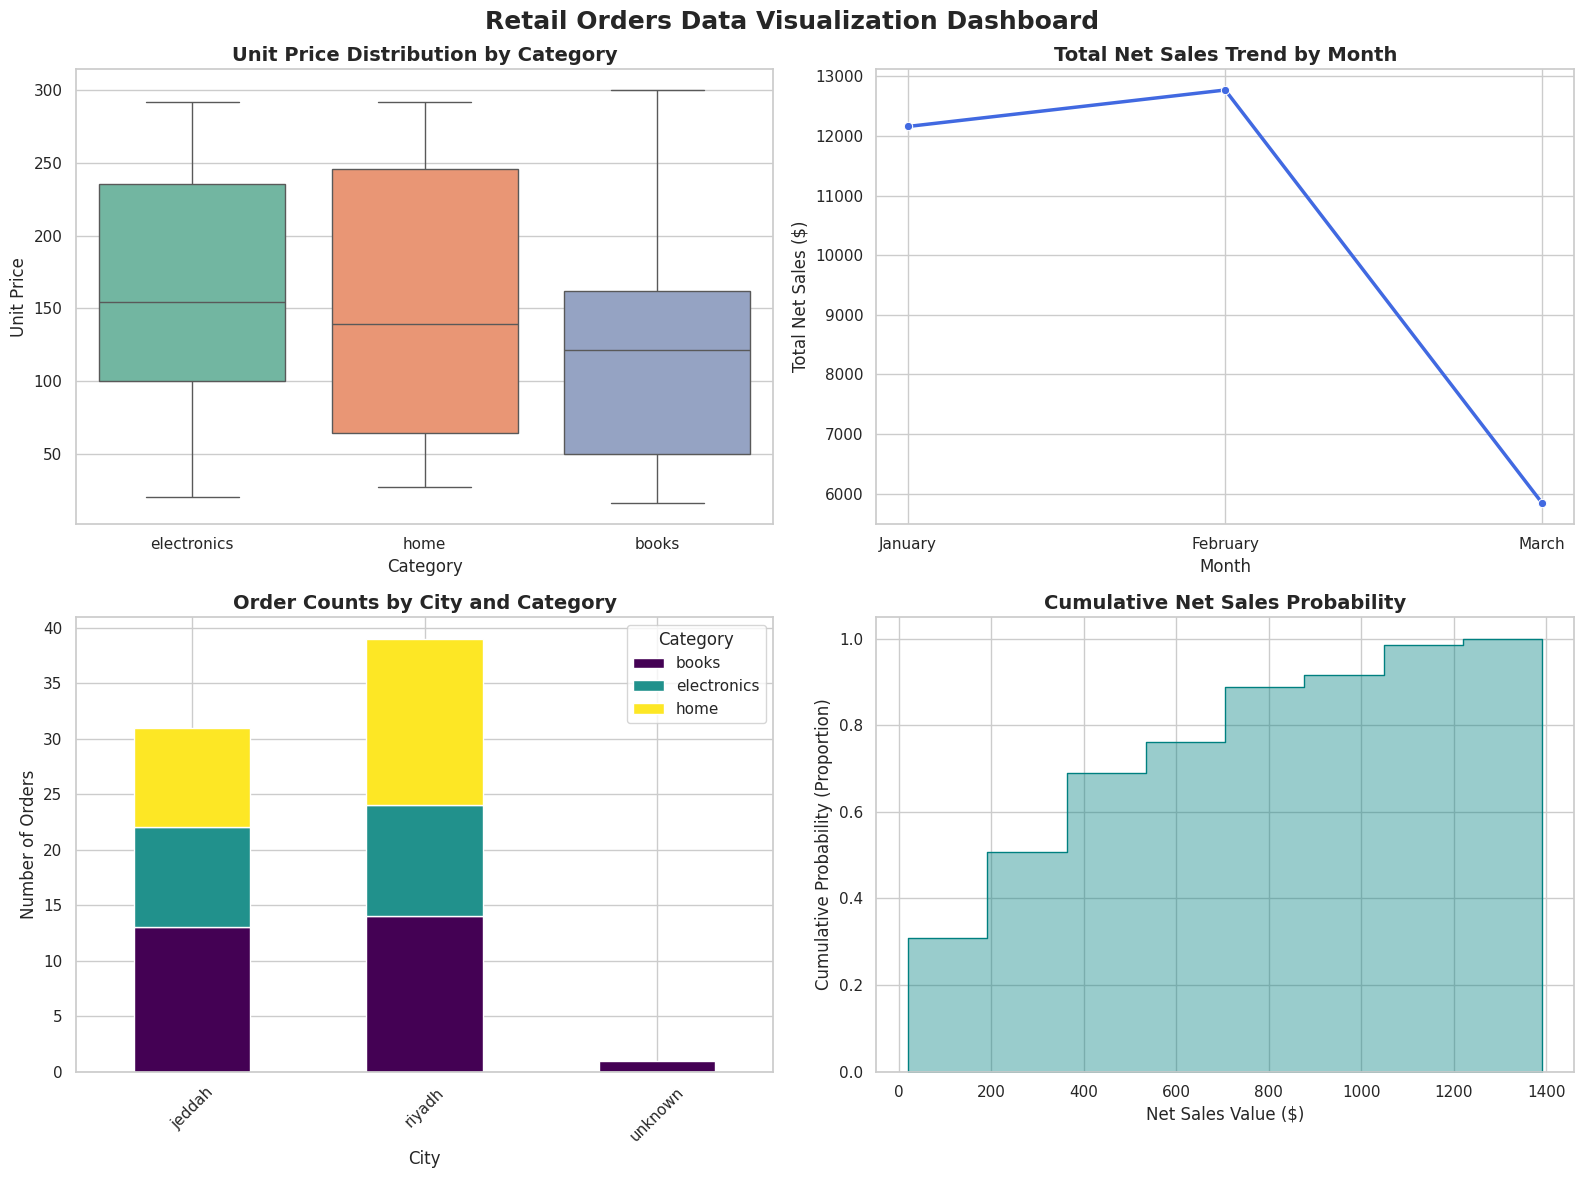

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set the styling style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Retail Orders Data Visualization Dashboard", fontsize=18, fontweight="bold", y=0.98)

# 1. Box plot of unit_price by category
sns.boxplot(ax=axes[0, 0], data=df, x='category', y='unit_price', palette='Set2')
axes[0, 0].set_title("Unit Price Distribution by Category", fontsize=14, fontweight="bold")
axes[0, 0].set_xlabel("Category", fontsize=12)
axes[0, 0].set_ylabel("Unit Price", fontsize=12)

# 2. Line chart of total net_sales by month in chronological order
month_order = ['January', 'February', 'March']
monthly_sales_ordered = df.groupby('month')['net_sales'].sum().reindex(month_order).reset_index()
sns.lineplot(ax=axes[0, 1], data=monthly_sales_ordered, x='month', y='net_sales', marker='o', linewidth=2.5, color='royalblue')
axes[0, 1].set_title("Total Net Sales Trend by Month", fontsize=14, fontweight="bold")
axes[0, 1].set_xlabel("Month", fontsize=12)
axes[0, 1].set_ylabel("Total Net Sales ($)", fontsize=12)

# 3. Stacked bar chart of order counts by city, category shown by color
# Prepare crosstab data for stacked bar plotting (excluding the margin 'Total')
city_cat_counts = pd.crosstab(df['city'], df['category'])
city_cat_counts.plot(kind='bar', stacked=True, ax=axes[1, 0], colormap='viridis')
axes[1, 0].set_title("Order Counts by City and Category", fontsize=14, fontweight="bold")
axes[1, 0].set_xlabel("City", fontsize=12)
axes[1, 0].set_ylabel("Number of Orders", fontsize=12)
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend(title="Category")

# 4. Cumulative histogram of net_sales using cumulative=True and stat="probability"
sns.histplot(
    ax=axes[1, 1],
    data=df,
    x='net_sales',
    cumulative=True,
    stat='probability',
    element='step',
    fill=True,
    color='teal',
    alpha=0.4
)
axes[1, 1].set_title("Cumulative Net Sales Probability", fontsize=14, fontweight="bold")
axes[1, 1].set_xlabel("Net Sales Value ($)", fontsize=12)
axes[1, 1].set_ylabel("Cumulative Probability (Proportion)", fontsize=12)

plt.tight_layout()
plt.show()